# Figure S2

Panels A-E: SNR of lamina and medulla triplets, same vs combined polarity triplets, and the natural movie decoder for triplets.

Data: the luminance traces extracted from the Chicago Motion Database movies (https://cmd.rcc.uchicago.edu/; Salisbury & Palmer, 2016). Set `PATH_TRACES` to their folder.

The SNR per band of all triplets (`PrecomputedSNR/`) and the held-out R² of the decoder for the 30 filter draws (`PATH_R2_CACHE`) are recomputed if missing. The SNR functions (Eqs. 20, 21) are defined in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`.

`FitParameters/` has the 30 filters per cell type.

In [ ]:
import colorsys
import hashlib
import pickle
import re
from itertools import combinations_with_replacement
from pathlib import Path

import numpy as np
import scipy.signal as signal
from scipy.interpolate import interp1d
from scipy.stats import wilcoxon
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.figure import Figure
from matplotlib.font_manager import FontProperties
from matplotlib.backends.backend_agg import FigureCanvasAgg

for key, val in {'font.family': 'sans-serif', 'font.sans-serif': ['Arial'], 'font.size': 12,
                 'axes.titlesize': 12, 'axes.labelsize': 12, 'xtick.labelsize': 12,
                 'ytick.labelsize': 12, 'legend.fontsize': 12, 'pdf.fonttype': 42, 'ps.fonttype': 42,
                 'axes.spines.top': False, 'axes.spines.right': False}.items():
    matplotlib.rcParams[key] = val

# Paths
PATH_TRACES = Path('Traces_flysigma') 
PATH_SNR_CACHE = Path('PrecomputedSNR')
PATH_R2_CACHE = Path('_jointdecoder_cache')
PATH_PARAMS = Path('FitParameters')
PATH_PDF = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)
PATH_SNR_CACHE.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237',
             'green': '#808233', 'yellow': '#f6eb16', 'orange': '#faa51a'}


def shade(hex_color, factor):
    r, g, b = matplotlib.colors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    return colorsys.hls_to_rgb(h, float(np.clip(l * factor, 0.05, 0.88)), s)


COLOR_PATHWAY = {'Lamina': COLOR_REF['green'], 'ON Medulla': COLOR_REF['yellow'],
                 'OFF Medulla': COLOR_REF['orange']}
PATHWAY_LEGEND = {'Lamina': 'Lamina', 'ON Medulla': 'Medulla, ON', 'OFF Medulla': 'Medulla, OFF'}
COLOR_POLARITY = {'double': COLOR_REF['blue'], 'single': COLOR_REF['red']}
COLOR_CLASS = {'D': COLOR_REF['blue'], 'S': COLOR_REF['red'], 'M': '#8c1a8e'}
CLASS_NAME = {'D': 'Double', 'S': 'Single', 'M': 'Combined'}
MARKER, MS = 's', 7.5

# Axes sizes in printed inches, times SCALE
SCALE = 12.0 / 7.4
BOX_PRINT = {'A': (1.25, 0.583), 'B': (2.44, 0.583), 'C': (0.538, 0.854)}
def box(k):
    return (BOX_PRINT[k][0] * SCALE, BOX_PRINT[k][1] * SCALE)
M_L, M_R, M_T = 0.80, 0.14, 0.18
SEP = 0.163 * SCALE + 0.42


def axes_inches(fig, left, bottom, width, height):
    W, H = fig.get_size_inches()
    return fig.add_axes([left / W, bottom / H, width / W, height / H])

## Analytic SNR of the triplets

In [3]:
GEN_FILTERS = 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt'
CIRCUITS = {'Lamina': ['L1', 'L2', 'L3'],
            'ON Medulla': ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
            'OFF Medulla': ['Tm2', 'Tm1', 'Tm4', 'Tm9']}
ALL_NAMES = [n for ns in CIRCUITS.values() for n in ns]
DOUBLE_POLARITY = ['L1', 'L2', 'Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
polarity = {nm: ('double' if nm in DOUBLE_POLARITY else 'single') for nm in ALL_NAMES}

N_ORDER, SIGMA_W = 4, 1.0
STANDARD_DT, STANDARD_NG = 0.01, 2**15
BANDS = {'III': ((1e-2, 1e0), STANDARD_DT, STANDARD_NG),
         'LF': ((10 ** -1.95, 10 ** -1.95 * 100), STANDARD_DT, STANDARD_NG),
         'F': ((10 ** (-5 / 3), 10 ** (1 / 3)), STANDARD_DT, STANDARD_NG),
         'E': ((10 ** (-4 / 3), 10 ** (2 / 3)), STANDARD_DT, STANDARD_NG),
         'I': ((1e-1, 1e1), STANDARD_DT, STANDARD_NG),
         'A': ((10 ** (-2 / 3), 10 ** (4 / 3)), STANDARD_DT, STANDARD_NG),
         'B': ((10 ** (-1 / 3), 10 ** (5 / 3)), STANDARD_DT, STANDARD_NG),
         'II': ((1e0, 1e2), 0.001, 2**19)}  # 8 bands, 0.01-100 Hz
REF_BAND, REF_TAUS = (1e-2, 1e1), ((0.01, 0.1), (20.0, 100.0), (0.5, 0.0))
NOISE_GRID = np.geomspace(1e-3, 1e1, 25)  # sigma_N^2 / var(s_ref), the levels stored in the cache
SIGMA_N2, K = 2.15, -1.6
CHUNK = 2**16


def folded_freq(N, dt):
    f = np.arange(N) / (N * dt)
    return np.minimum(f, 1.0 / dt - f)


def band_cutoff(f, band_hz):
    O = 2 * np.pi * np.asarray(f)
    WL, WH = band_hz
    w0, B = 2 * np.pi * np.sqrt(WL * WH), 2 * np.pi * (WH - WL)
    return 1 / np.sqrt(1 + ((O ** 2 - w0 ** 2) / (B * O + np.spacing(1))) ** (2 * N_ORDER))


def stimulus_power_law(N, dt, band_hz, k):
    f = folded_freq(N, dt)
    with np.errstate(divide='ignore'):
        raw = np.where(f > 0, SIGMA_W ** 2 * f ** k, 0.0)
    return raw * band_cutoff(f, band_hz) ** 2


def reference_spectrum(N, dt):
    O = 2 * np.pi * folded_freq(N, dt)
    C = band_cutoff(folded_freq(N, dt), REF_BAND)
    terms = sum((a / (1 + 1j * O * ta)) * (b / (1 - 1j * O * tb))
                for ta, a in REF_TAUS for tb, b in REF_TAUS)
    return np.real(SIGMA_W ** 2 * C ** 2 * terms)


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


def filter_TF(N, dt, tau1, tau2, rho_):
    # scaled to the gain of the 10 ms sampling step
    return np.fft.fft(filter_function(np.arange(N) * dt, tau1, tau2, rho_)) * (dt / STANDARD_DT)


def load_generated():
    # columns: cell_type k A_t tau_t A_fit tau_fit tau1 tau2 rho_
    by_type = {}
    with open(PATH_PARAMS / GEN_FILTERS) as fh:
        for line in fh:
            if line.strip() and not line.lstrip().startswith('#'):
                F = line.split()
                by_type.setdefault(F[0], []).append(
                    dict(tau1=float(F[6]), tau2=float(F[7]), rho_=float(F[8])))
    return {n: by_type[n] for n in ALL_NAMES}


ENS = load_generated()
N_REAL = len(ENS[ALL_NAMES[0]])

TRIP = {c: ['-'.join(t) for t in combinations_with_replacement(ns, 3)] for c, ns in CIRCUITS.items()}
ALL_TRIP = [(c, l) for c in CIRCUITS for l in TRIP[c]]
IDX_T = {k: i for i, k in enumerate(ALL_TRIP)}


def pol_class(label):
    # 'D' all double polarity, 'S' all single, 'M' combined
    p = {polarity[nm][0].upper() for nm in label.split('-')}
    return p.pop() if len(p) == 1 else 'M'


def redundant(label):
    return len(set(label.split('-'))) == 1


TAG = hashlib.sha256(open(PATH_PARAMS / GEN_FILTERS, 'rb').read()).hexdigest()[:12]


def log_snr_band(k, bname):
    # (noise levels, triplets, draws) log SNR on one band
    cache = (PATH_SNR_CACHE / f'snrF3_dtfix_{TAG}_a{-k:g}_band{bname}_'
                              f'{len(NOISE_GRID)}n_{len(ALL_TRIP)}t.pkl')
    if cache.exists():
        return pickle.load(open(cache, 'rb'))
    band_hz, dt, ng = BANDS[bname]
    S = stimulus_power_law(ng, dt, band_hz, k)
    sig = NOISE_GRID * reference_spectrum(STANDARD_NG, STANDARD_DT).mean()
    acc = np.zeros((len(NOISE_GRID), len(ALL_TRIP), N_REAL))
    for ri in range(N_REAL):
        P = {nm: np.abs(filter_TF(ng, dt, **ENS[nm][ri])) ** 2 for nm in ALL_NAMES}
        for pi, (_, lab) in enumerate(ALL_TRIP):
            u, tot = S * sum(P[nm] for nm in lab.split('-')), np.zeros(len(NOISE_GRID))
            for s0 in range(0, ng, CHUNK):
                blk = slice(s0, min(s0 + CHUNK, ng))
                tot += (S[blk] / (u[blk] + sig[:, None])).sum(axis=1)
            acc[:, pi, ri] = np.log(S.mean() / (sig * tot / ng))
    pickle.dump(acc, open(cache, 'wb'))
    return acc


i_noise = int(np.argmin(np.abs(NOISE_GRID - SIGMA_N2)))
logsnr = np.mean([log_snr_band(K, b)[i_noise] for b in BANDS], axis=0)  # (triplets, draws)
SNR_T = {k: float(np.exp(logsnr[IDX_T[k]].mean())) for k in ALL_TRIP}  # geometric mean over draws
ORDER = {c: sorted(TRIP[c], key=lambda l: SNR_T[(c, l)]) for c in CIRCUITS}

## Fig. S2A, B

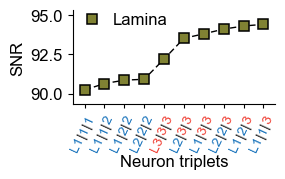

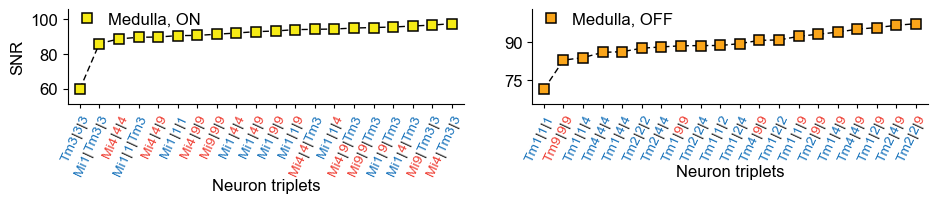

In [4]:
MEASURE = Figure(dpi=72)
FigureCanvasAgg(MEASURE)
RENDERER = MEASURE.canvas.get_renderer()
W_CACHE, H_CACHE = {}, {}
TICK_ROT, TICK_PAD, TICK_LEN, TICK_FS = 65, 3.5, 3.0, 10


def text_width_pt(s, fontsize):
    if not s:
        return 0.0
    if (s, fontsize) not in W_CACHE:
        W_CACHE[(s, fontsize)] = RENDERER.get_text_width_height_descent(
            s, FontProperties(family='Arial', size=fontsize), False)[0]
    return W_CACHE[(s, fontsize)]


def text_extent_pt(s, fontsize):
    if (s, fontsize) not in H_CACHE:
        _, h, d = RENDERER.get_text_width_height_descent(
            s, FontProperties(family='Arial', size=fontsize), False)
        H_CACHE[(s, fontsize)] = (h - d, d)
    return H_CACHE[(s, fontsize)]


def split_name(ct):
    m = re.match(r'([A-Za-z]+)(\d+)', ct)
    return m.group(1), int(m.group(2))


def circuit_tokens(label, sep='|'):
    # [(text, colour)]: shared prefix written once ('Mi4|9|Tm3'), names in their polarity colour
    members = sorted(label.split('-'), key=split_name)
    out, prev = [], None
    for nm in members:
        prefix = split_name(nm)[0]
        if out:
            out.append((sep, 'k'))
        out.append((nm if prefix != prev else nm[len(prefix):], COLOR_POLARITY[polarity[nm]]))
        prev = prefix
    return out


def label_geometry(token_lists, fontsize):
    fulls = [''.join(t for t, _ in toks) for toks in token_lists]
    return (max(text_width_pt(s, fontsize) for s in fulls),
            max(text_extent_pt(s, fontsize)[0] for s in fulls),
            max(text_extent_pt(s, fontsize)[1] for s in fulls))


def xticklabel_height(token_lists, fontsize=TICK_FS):
    th = np.deg2rad(TICK_ROT)
    widest, top, desc = label_geometry(token_lists, fontsize)
    return (TICK_LEN + TICK_PAD + (top + desc) * np.cos(th) + widest * np.sin(th)) / 72.0


def multicolor_xticklabels(ax, xs, token_lists, fontsize=TICK_FS):
    th = np.deg2rad(TICK_ROT)
    ux, uy, nx, ny = np.cos(th), np.sin(th), -np.sin(th), np.cos(th)
    _, top, _ = label_geometry(token_lists, fontsize)
    ex, ey = -top * nx, -(TICK_LEN + TICK_PAD) - top * ny
    ax.set_xticks(list(xs))
    ax.set_xticklabels([''] * len(xs))
    for x, toks in zip(xs, token_lists):
        full = ''.join(t for t, _ in toks)
        total = text_width_pt(full, fontsize)
        for k, (text, col) in enumerate(toks):
            d = text_width_pt(full[:sum(len(t) for t, _ in toks[:k])], fontsize) - total
            ax.annotate(text, xy=(x, 0), xycoords=ax.get_xaxis_transform(),
                        xytext=(ex + d * ux, ey + d * uy), textcoords='offset points',
                        rotation=TICK_ROT, rotation_mode='anchor', ha='left', va='baseline',
                        color=col, fontsize=fontsize, annotation_clip=False)


def order_axis(ax, pathway):
    toks = [circuit_tokens(l) for l in ORDER[pathway]]
    multicolor_xticklabels(ax, range(len(toks)), toks)
    ax.set_xlabel('Neuron triplets', labelpad=xticklabel_height(toks) * 72 - 6)
    ax.tick_params(axis='x', length=TICK_LEN)
    ax.set_xlim(-0.6, len(toks) - 0.4)


def figure_row(pathways, width, height, draw):
    blk = max(xticklabel_height([circuit_tokens(l) for l in TRIP[p]]) for p in pathways) + 0.38
    n = len(pathways)
    fig = plt.figure(figsize=(M_L + n * width + SEP * (n - 1) + M_R, blk + height + M_T))
    for i, p in enumerate(pathways):
        draw(axes_inches(fig, M_L + i * (width + SEP), blk, width, height), p, i == 0)
    return fig


def draw_snr(ax, pathway, first):
    y = [SNR_T[(pathway, l)] for l in ORDER[pathway]]
    x = np.arange(len(y))
    ax.plot(x, y, ls=(0, (4.5, 2.5)), color='k', lw=1.0, zorder=2)
    ax.plot(x, y, ls='none', marker=MARKER, ms=MS, mfc=COLOR_PATHWAY[pathway], mec='k',
            mew=1.1, zorder=3)
    order_axis(ax, pathway)
    if first:
        ax.set_ylabel('SNR')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.margins(y=0.22)
    ax.legend(handles=[Line2D([], [], ls='none', marker=MARKER, ms=MS, mfc=COLOR_PATHWAY[pathway],
                              mec='k', mew=1.1, label=PATHWAY_LEGEND[pathway])],
              loc='upper left', frameon=False, handletextpad=0.25, borderpad=0.0,
              borderaxespad=0.15)


Fig = figure_row(['Lamina'], *box('A'), draw_snr)
Fig.savefig(PATH_PDF / 'FigS2A_SNR_Lamina.pdf', bbox_inches='tight', transparent=True)
plt.show()
Fig = figure_row(['ON Medulla', 'OFF Medulla'], *box('B'), draw_snr)
Fig.savefig(PATH_PDF / 'FigS2B_SNR_Medulla.pdf', bbox_inches='tight', transparent=True)
plt.show()

## Fig. S2C

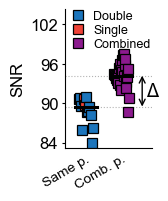

same n = 13, combined n = 26; Delta = +5.26%


In [5]:
GROUPS = (('Same p.', ('D', 'S')), ('Comb. p.', ('M',)))


def polarity_split(keys, value):
    # [(values, keys)] of the same- and combined-polarity groups, redundant triplets excluded
    out = []
    for _, classes in GROUPS:
        ks = [k for k in keys if not redundant(k[1]) and pol_class(k[1]) in classes]
        out.append((np.array([value(k) for k in ks]), ks))
    return out


def polarity_panel(groups, centre, ylabel):
    wA, bh = box('C')
    fig = plt.figure(figsize=(M_L + wA + M_R, 0.78 + bh + M_T))
    ax = axes_inches(fig, M_L, 0.78, wA, bh)
    cen = []
    for gi, (vals, keys) in enumerate(groups):
        for x0, y0, k0 in zip(gi + np.linspace(-0.20, 0.20, vals.size), vals, keys):
            ax.plot(x0, y0, MARKER, ms=6.5, mfc=COLOR_CLASS[pol_class(k0[1])], mec='k', mew=0.9,
                    zorder=3)
        cen.append(float(centre(vals)))
        ax.axhline(cen[-1], color='0.7', lw=0.8, ls=':', zorder=1)
        ax.plot([gi - 0.30, gi + 0.30], [cen[-1]] * 2, '-', color='k', lw=2.2, zorder=4)

    ax.set_xlim(-0.60, 1.85)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([n for n, _ in GROUPS], fontsize=10, rotation=30, ha='right',
                       rotation_mode='anchor')
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y0 + (y1 - y0) * 1.42)
    ax.tick_params(axis='x', length=0)
    ax.tick_params(axis='y', length=2.5, pad=2)
    span_pt = abs(np.diff(ax.transData.transform([(0, cen[0]), (0, cen[1])])[:, 1])[0])
    ax.annotate('', xy=(1.58, cen[1]), xytext=(1.58, cen[0]),
                arrowprops=dict(arrowstyle='<->', color='k', lw=1.0, shrinkA=0, shrinkB=0,
                                mutation_scale=min(12.0, 0.34 * span_pt)))
    ax.text(1.70, 0.5 * sum(cen), 'Δ', fontsize=13, va='center', ha='left')
    ax.legend(handles=[Line2D([], [], ls='none', marker=MARKER, ms=6.5, mfc=COLOR_CLASS[c],
                              mec='k', mew=0.9, label=CLASS_NAME[c]) for c in 'DSM'],
              loc='upper left', frameon=False, fontsize=9, handletextpad=0.2,
              labelspacing=0.15, borderpad=0.0, borderaxespad=0.1)
    return fig


POL_SNR = polarity_split(ALL_TRIP, lambda k: SNR_T[k])
Fig = polarity_panel(POL_SNR, np.median, 'SNR')
Fig.savefig(PATH_PDF / 'FigS2C_SNR_PolarityClass.pdf', bbox_inches='tight', transparent=True)
plt.show()

(snr_same, _), (snr_comb, _) = POL_SNR
print(f'same n = {snr_same.size}, combined n = {snr_comb.size}; '
      f'Delta = {100 * (np.median(snr_comb) / np.median(snr_same) - 1):+.2f}%')

## Natural-movie decoder on triplets

In [6]:
DT_FIXED = 0.01  # s
K_LAGS = 100  # decoder window 1 s
T_SKIP = 1.0  # s of transient dropped
TRAIN_FRAC = 0.7
REG = 10.0  # ridge penalty
SEED = 0
SIGMA_IN = 0.0
RESP_RATIO = 0.0343621  # sigma_N^2 / var(response)
COND_INDEX = 1

META = np.load(PATH_TRACES / 'TracePixelMeta.npz', allow_pickle=True)
MOVIES = [str(m) for m in META['movies']]
N_MOVIES = len(MOVIES)
N_PIX_TRACE = int(META['n_pix'])
T_MAX = np.array([float(META[f'{m}|duration']) for m in MOVIES])
TRACE_TIMEBASE = 1.0 * N_PIX_TRACE


def load_raw_luminance(i_movie):
    # 'raw' is filtered by the neurons; 'stim' (transient cut, z-scored) is the decoder target
    span = T_MAX[i_movie] * TRACE_TIMEBASE
    raw = np.loadtxt(PATH_TRACES / ('TracesNatural' + MOVIES[i_movie] + '_live.txt'))
    raw = np.reshape(np.transpose(raw), -1)
    T_arr = np.linspace(0, span, raw.size)
    cut = np.where(T_arr >= span)[0][0]
    raw, T_arr = raw[:cut], T_arr[:cut]
    n_t = int(T_arr[-1] / DT_FIXED)
    t_sig = np.arange(n_t) * DT_FIXED
    resampled = interp1d(T_arr, raw, kind='linear', fill_value='extrapolate')(t_sig)
    skip = int(T_SKIP / DT_FIXED)
    stim = resampled[skip:] - resampled[skip:].mean()
    return dict(t=t_sig, raw=resampled, stim=stim / stim.std(), n_t=n_t, skip=skip)


MOVIE_CACHE = {i: load_raw_luminance(i) for i in range(N_MOVIES)}


def response_scale():
    # per movie: geometric mean of var(h * raw) over cell types and draws
    out = np.zeros(N_MOVIES)
    for i_movie, mc in MOVIE_CACHE.items():
        v = [np.var(signal.convolve(mc['raw'], filter_function(mc['t'], **ENS[nm][r]),
                                    'full')[mc['skip']:mc['n_t']])
             for nm in ALL_NAMES for r in range(N_REAL)]
        out[i_movie] = np.exp(np.mean(np.log(v)))
    return out


def neuron_responses(i_real, sigma_out):
    # every cell type's z-scored noisy response to every movie, for one filter draw
    rng = np.random.default_rng([SEED, i_real, COND_INDEX])
    out = {}
    for i_movie in range(N_MOVIES):
        mc = MOVIE_CACHE[i_movie]
        n_t, sk = mc['n_t'], mc['skip']
        for nm in ALL_NAMES:
            F = filter_function(mc['t'], **ENS[nm][i_real])
            x = mc['raw'] if SIGMA_IN == 0 else mc['raw'] + rng.normal(scale=SIGMA_IN, size=n_t)
            net = signal.convolve(x, F, 'full')[:n_t] + rng.normal(scale=sigma_out[i_movie], size=n_t)
            net = net[sk:] - net[sk:].mean()
            out[(i_movie, nm)] = net / net.std()
    return out


def movie_weights(n_rows):
    # each movie counts equally in the pooled fit
    n = np.asarray(n_rows, float)
    return n.sum() / (len(n) * n)


CHUNK_ROWS = 16384


def movie_moments(channels, y):
    # cross-moments of one movie's lagged channels with the target, train and held-out parts
    V = [sliding_window_view(ch, K_LAGS) for ch in channels]
    T = len(y) - K_LAGS + 1
    y = np.asarray(y)[:T]
    n_tr, P = int(TRAIN_FRAC * T), K_LAGS * len(channels)
    mom = {}
    for part, (a0, a1) in (('tr', (0, n_tr)), ('te', (n_tr, T))):
        M = dict(G=np.zeros((P, P)), c=np.zeros(P), s=np.zeros(P), n=0.0, sy=0.0, syy=0.0)
        for a in range(a0, a1, CHUNK_ROWS):
            b = min(a + CHUNK_ROWS, a1)
            S, yy = np.hstack([v[a:b] for v in V]), y[a:b]
            M['G'] += S.T @ S; M['c'] += S.T @ yy; M['s'] += S.sum(axis=0)
            M['n'] += b - a; M['sy'] += yy.sum(); M['syy'] += yy @ yy
        mom[part] = M
    return mom


def lag_cols(cols):
    return np.concatenate([np.arange(j * K_LAGS, (j + 1) * K_LAGS) for j in cols])


def circuit_fit(moms, cols):
    # (w, b) of the pooled ridge decoder of the channels 'cols'
    idx = lag_cols(cols)
    alpha = movie_weights([m['tr']['n'] for m in moms])
    P = len(idx)
    G, c, s, n, sy = np.zeros((P, P)), np.zeros(P), np.zeros(P), 0.0, 0.0
    for m, ai in zip(moms, alpha):
        t = m['tr']
        G += ai * t['G'][np.ix_(idx, idx)]; c += ai * t['c'][idx]; s += ai * t['s'][idx]
        n += ai * t['n']; sy += ai * t['sy']
    S_mean, y_mean = s / n, sy / n
    w = np.linalg.solve(G - n * np.outer(S_mean, S_mean) + REG * np.eye(P), c - sy * S_mean)
    return w, y_mean - S_mean @ w


def circuit_r2(moms, cols):
    # held-out R^2 per movie
    idx = lag_cols(cols)
    w, b = circuit_fit(moms, cols)
    out = []
    for m in moms:
        t = m['te']
        ssr = (t['syy'] - 2 * w @ t['c'][idx] - 2 * b * t['sy'] + w @ t['G'][np.ix_(idx, idx)] @ w
               + 2 * b * w @ t['s'][idx] + t['n'] * b * b)
        out.append(1.0 - ssr / (t['syy'] - t['sy'] ** 2 / t['n']))
    return np.array(out)


def pathway_moments(resp, pathway):
    names = CIRCUITS[pathway]
    return [movie_moments([resp[(i, nm)] for nm in names], MOVIE_CACHE[i]['stim'])
            for i in range(N_MOVIES)]


def cols_of(pathway, label):
    return [CIRCUITS[pathway].index(nm) for nm in label.split('-')]
PAIRS = {c: ['-'.join(p) for p in combinations_with_replacement(ns, 2)] for c, ns in CIRCUITS.items()}
ALL_PAIRS = [(c, l) for c in CIRCUITS for l in PAIRS[c]]

cache_key = [hashlib.sha256(open(PATH_PARAMS / GEN_FILTERS, 'rb').read()).hexdigest(),
             MOVIES, T_MAX.tolist(), TRACE_TIMEBASE, DT_FIXED, K_LAGS, T_SKIP,
             TRAIN_FRAC, REG, SIGMA_IN, ('resp', RESP_RATIO), SEED,
             ('npix', N_PIX_TRACE), ('weights', 'equal-per-movie'), ('traces', PATH_TRACES.name),
             ('circuits', 'pairs+triplets')]
TRIP_CACHE = PATH_R2_CACHE / f'r2T_{hashlib.sha256(repr(cache_key).encode()).hexdigest()[:16]}.pkl'

if TRIP_CACHE.exists():
    SWEEP = pickle.load(open(TRIP_CACHE, 'rb'))
else:
    s_out = np.sqrt(RESP_RATIO * response_scale())
    R2P = np.zeros((N_REAL, len(ALL_PAIRS), N_MOVIES))
    R2T = np.zeros((N_REAL, len(ALL_TRIP), N_MOVIES))
    for r in range(N_REAL):
        resp = neuron_responses(r, s_out)
        for pw in CIRCUITS:
            moms = pathway_moments(resp, pw)
            for j, key in enumerate(ALL_PAIRS):
                if key[0] == pw:
                    R2P[r, j] = circuit_r2(moms, cols_of(*key))
            for j, key in enumerate(ALL_TRIP):
                if key[0] == pw:
                    R2T[r, j] = circuit_r2(moms, cols_of(*key))
            del moms
        del resp
    SWEEP = dict(R2_pairs=R2P, R2_trip=R2T, s_out=s_out, pairs=ALL_PAIRS, trip=ALL_TRIP)
    pickle.dump(SWEEP, open(TRIP_CACHE, 'wb'))

R2_MOVIE = SWEEP['R2_trip'].mean(axis=0)  # (triplets, movies), mean over draws
R2_T = {k: R2_MOVIE[IDX_T[k]] for k in ALL_TRIP}

## Fig. S2D

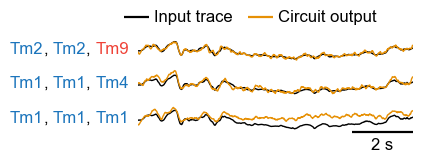

In [7]:
TRACE_MOVIE, TRACE_DRAW, TRACE_PATHWAY = '1_bushes', 0, 'OFF Medulla'
SD_FLOOR, HF_CUT, SCALE_BAR = 0.25, 0.8, 2.0
C_TRACE_STIM, C_TRACE_OUT = 'k', shade(COLOR_REF['orange'], 0.85)
SEG_GUARD = K_LAGS * DT_FIXED

# highest SNR; lowest non-redundant same-polarity; lowest redundant
def snr_of(l):
    return SNR_T[(TRACE_PATHWAY, l)]
TRACE_TRIPS = (max(TRIP[TRACE_PATHWAY], key=snr_of),
               min((l for l in TRIP[TRACE_PATHWAY] if not redundant(l) and pol_class(l) != 'M'), key=snr_of),
               min((l for l in TRIP[TRACE_PATHWAY] if redundant(l)), key=snr_of))

RESP0 = neuron_responses(TRACE_DRAW, SWEEP['s_out'])
moms0 = pathway_moments(RESP0, TRACE_PATHWAY)
FITS = {l: circuit_fit(moms0, cols_of(TRACE_PATHWAY, l)) for l in TRACE_TRIPS}
del moms0


def held_out(label, i_movie):
    # (t, target, decoded) on the held-out portion
    w, b = FITS[label]
    chans = [RESP0[(i_movie, nm)] for nm in label.split('-')]
    dec = b + sum(signal.correlate(ch, w[j * K_LAGS:(j + 1) * K_LAGS], mode='valid')
                  for j, ch in enumerate(chans))
    y = MOVIE_CACHE[i_movie]['stim'][:len(dec)]
    n_tr = int(TRAIN_FRAC * len(y))
    t = (MOVIE_CACHE[i_movie]['skip'] + np.arange(len(y))) * DT_FIXED
    return t[n_tr:], y[n_tr:], dec[n_tr:]


def hf_fraction(y, cut=HF_CUT):
    y = np.asarray(y, float) - np.mean(y)
    if y.std() < 1e-9:
        return np.nan
    P = np.abs(np.fft.rfft(y * np.hanning(len(y)))) ** 2
    return float(P[np.fft.rfftfreq(len(y), DT_FIXED) > cut].sum() / P.sum())


def seam_free_window(i_movie, t, target):
    # one pixel's stretch: median high-frequency power among stretches with SD >= SD_FLOOR
    L, whole = T_MAX[i_movie] * TRACE_TIMEBASE / N_PIX_TRACE, []
    seg = np.ceil(t[0] / L) * L
    while seg + L <= t[-1]:
        m = (t >= seg + SEG_GUARD) & (t < seg + L)
        if m.sum() > 10:
            whole.append(dict(sd=float(np.std(target[m])), hf=hf_fraction(target[m]), seg=seg))
        seg += L
    keep = [c for c in whole if c['sd'] >= SD_FLOOR and np.isfinite(c['hf'])] or whole
    med = float(np.median([c['hf'] for c in keep]))
    seg = min(keep, key=lambda c: abs(c['hf'] - med))['seg']
    return seg + SEG_GUARD, seg + L


# Layout in printed points (y down)
E_SIZE = (192.0, 64.8)
E_TRACE_X, E_LABEL_X = (70.0, 192.0), 66.0
E_ROWS = ((12.3, 25.4), (27.0, 40.9), (42.6, 56.5))
E_LEG_Y, E_LEG = 4.8, (((64.0, 75.0), 77.0, 'Input trace'), ((119.0, 130.0), 132.0, 'Circuit output'))
E_BAR_Y = 55.8


def pt(x, y):
    return x / E_SIZE[0], 1 - y / E_SIZE[1]


def text_tokens(fig, xy, tokens, fontsize=12):
    # one right-aligned line, each token in its own colour
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    fp = FontProperties(family='Arial', size=fontsize)
    w = [r.get_text_width_height_descent(t, fp, False)[0] * 72.0 / fig.dpi for t, _ in tokens]
    fw = fig.get_size_inches()[0] * 72.0
    x = xy[0] - sum(w) / fw
    for (txt, col), wi in zip(tokens, w):
        fig.text(x, xy[1], txt, color=col, fontsize=fontsize, ha='left', va='center')
        x += wi / fw


def named_tokens(label):
    toks = []
    for nm in sorted(label.split('-'), key=split_name):
        toks += ([(', ', 'k')] if toks else []) + [(nm, COLOR_POLARITY[polarity[nm]])]
    return toks


def panel_traces(movie=TRACE_MOVIE, trips=TRACE_TRIPS):
    i_movie = MOVIES.index(movie)
    fig = plt.figure(figsize=(E_SIZE[0] * SCALE / 72, E_SIZE[1] * SCALE / 72))
    t, y, _ = held_out(trips[0], i_movie)
    t0, t1 = seam_free_window(i_movie, t, y)
    for (lx0, lx1), tx, txt in E_LEG:
        col = C_TRACE_STIM if txt == 'Input trace' else C_TRACE_OUT
        (a0, b0), (a1, _) = pt(lx0, E_LEG_Y), pt(lx1, E_LEG_Y)
        fig.add_artist(Line2D([a0, a1], [b0, b0], transform=fig.transFigure, color=col, lw=1.6,
                              solid_capstyle='butt'))
        fig.text(*pt(tx, E_LEG_Y), txt, ha='left', va='center', fontsize=12)

    lo, hi, axs = np.inf, -np.inf, []
    for label, (ya, yb) in zip(trips, E_ROWS):
        x0, y0 = pt(E_TRACE_X[0], yb)
        x1, y1 = pt(E_TRACE_X[1], ya)
        ax = fig.add_axes([x0, y0, x1 - x0, y1 - y0])
        t, y, d = held_out(label, i_movie)
        m = (t >= t0) & (t < t1)
        ax.plot(t[m], y[m], color=C_TRACE_STIM, lw=1.0)
        ax.plot(t[m], d[m], color=C_TRACE_OUT, lw=1.0)
        ax.set_axis_off()
        lo, hi = min(lo, y[m].min(), d[m].min()), max(hi, y[m].max(), d[m].max())
        axs.append(ax)
        text_tokens(fig, pt(E_LABEL_X, 0.5 * (ya + yb)), named_tokens(label))
    for ax in axs:
        ax.set_xlim(t0, t1)
        ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))

    bx0 = E_TRACE_X[1] - (E_TRACE_X[1] - E_TRACE_X[0]) * SCALE_BAR / (t1 - t0)
    (a0, b0), (a1, _) = pt(bx0, E_BAR_Y), pt(E_TRACE_X[1], E_BAR_Y)
    fig.add_artist(Line2D([a0, a1], [b0, b0], transform=fig.transFigure, color='k', lw=1.6,
                          solid_capstyle='butt'))
    fig.text(0.5 * (a0 + a1), b0 - 0.035, f'{SCALE_BAR:g} s', ha='center', va='top', fontsize=12)
    return fig


Fig = panel_traces()
Fig.savefig(PATH_PDF / 'FigS2D_Traces_OFF.pdf', transparent=True)
plt.show()

## Fig. S2E

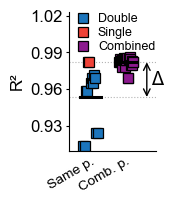

Delta = +2.99%, 10/10 videos positive, one-sided Wilcoxon p = 0.000977


In [8]:
POL_R2 = polarity_split(ALL_TRIP, lambda k: R2_T[k].mean())
Fig = polarity_panel(POL_R2, np.mean, 'R²')
Fig.savefig(PATH_PDF / 'FigS2E_R2_PolarityClass.pdf', bbox_inches='tight', transparent=True)
plt.show()

(r2_same, keys_same), (r2_comb, keys_comb) = POL_R2
gap = np.mean([R2_T[k] for k in keys_comb], axis=0) - np.mean([R2_T[k] for k in keys_same], axis=0)
print(f'Delta = {100 * (r2_comb.mean() / r2_same.mean() - 1):+.2f}%, '
      f'{int((gap > 0).sum())}/{N_MOVIES} videos positive, '
      f'one-sided Wilcoxon p = {wilcoxon(gap, alternative="greater").pvalue:.3g}')